<a href="https://colab.research.google.com/github/Thathsara-Devindi/Diabetes-ML-Baseline/blob/main/Phase2_Baseline_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2: Technical Application
## Baseline Implementation for Multiclass Diabetes Prediction

Selected Paper:
Prediction of diabetes disease using an ensemble of machine learning multi-classifier models, Abnoosian et al. (2023)

Implement Random Forest (RF) and Logistic Regression (LR) baselines, test minority-class performance and compare results with the paper's published AUC-weighted ensemble. An RF + LR equal weight/AUC-weight experiment is included as an exploratory extension, not an exact reproduction of the authors' four-model ensemble.

**Software flow:**

pandas (load/clean) -> scikit-learn (split, preprocessing, train and validate) -> NumPy (combine probabilities) -> scikit-learn metrics/Matplotlib (evaluate/plot) -> joblib, CSV and JSON (save and verify)

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.preprocessing import label_binarize

import joblib

RANDOM_STATE = 42

print("Libraries loaded successfully.")

Libraries loaded successfully.


# 1. Dataset source and loading

This public CSV has 14 raw columns and 1000 records. It has ID fields, clinical predictors and outcome (CLASS) is a 3 class outcome. This public working data differs from the authors' modified working data, as it does not include FBS values obtained separately by the authors. but does include a Urea and VLDL



In [54]:
# Upload the dataset
uploaded = files.upload()

uploaded_filename = next(iter(uploaded))
print("Uploaded file:", uploaded_filename)

if uploaded_filename.lower().endswith(".csv"):
    df = pd.read_csv(uploaded_filename)
elif uploaded_filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(uploaded_filename)
else:
    raise ValueError("Please upload the CSV or Excel dataset file.")

print("\nDataset shape:", df.shape)
display(df.head())

Saving Dataset of Diabetes .csv to Dataset of Diabetes  (1).csv
Uploaded file: Dataset of Diabetes  (1).csv

Dataset shape: (1000, 14)


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


In [55]:
 # Audit the dataset
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Column names:
['ID', 'No_Pation', 'Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI', 'CLASS']

Data types:
ID             int64
No_Pation      int64
Gender        object
AGE            int64
Urea         float64
Cr             int64
HbA1c        float64
Chol         float64
TG           float64
HDL          float64
LDL          float64
VLDL         float64
BMI          float64
CLASS         object
dtype: object

Missing values per column:
ID           0
No_Pation    0
Gender       0
AGE          0
Urea         0
Cr           0
HbA1c        0
Chol         0
TG           0
HDL          0
LDL          0
VLDL         0
BMI          0
CLASS        0
dtype: int64

Exact duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null

The raw-row duplicate count includes identifiers and is therefore zero. This does not imply there are no repeated clinical profiles. Identifiers are removed before the duplicate profile audit below. Standard parsed missing values are absent

# 2. Clean records and define the three class target

Normalise column and category text, remove non-predictive identifiers (ID, No_Pation), remove repeated clinical profiles and map N=0, P=1, Y=2.

After eliminating repetitions (not necessarily 174 duplicate persons) from the public data, 826 distinct profiles emerge. Class proportions are skewed, so stratification and minority sensitive metrics are both relevant

In [56]:
# Clean the column names
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(df.columns.tolist())

['ID', 'No_Pation', 'Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI', 'CLASS']


In [57]:
# Find target column
possible_targets = ["CLASS", "Class", "class", "Target", "target"]

target_col = None
for col in possible_targets:
    if col in df.columns:
        target_col = col
        break

if target_col is None:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

print("Target column:", target_col)
print("\nRaw class distribution:")
print(df[target_col].value_counts(dropna=False))

# Remove obvious identifier columns
identifier_candidates = [
    "ID", "Id", "id",
    "No_Pation", "No_Patient",
    "Patient_ID", "PatientID"
]

id_cols = [c for c in identifier_candidates if c in df.columns]

print("\nIdentifier columns removed:", id_cols)

df_model = df.drop(columns=id_cols).copy()

Target column: CLASS

Raw class distribution:
CLASS
Y     840
N     102
P      53
Y       4
N       1
Name: count, dtype: int64

Identifier columns removed: ['ID', 'No_Pation']


In [58]:
# Step 1 - Clean text values

df_model["Gender"] = (
    df_model["Gender"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df_model["CLASS"] = (
    df_model["CLASS"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Step 2 - Remove duplicate clinical records

rows_before = len(df_model)

df_model = df_model.drop_duplicates().reset_index(drop=True)

rows_after = len(df_model)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Duplicates removed:", rows_before - rows_after)

print("\nClass distribution:")
print(df_model["CLASS"].value_counts())


Rows before cleaning: 1000
Rows after cleaning: 826
Duplicates removed: 174

Class distribution:
CLASS
Y    690
N     96
P     40
Name: count, dtype: int64


**Cleaning result**  - 174 repeated clinical records are removed from the 1000-row public file after standardizing categories and excluding ID columns, leaving 826 distinct clinical profiles. The 174 removals must not be described as confirmed duplicate patients.

In [59]:
print(df_model[target_col].unique())
print(df_model[target_col].value_counts())

['N' 'P' 'Y']
CLASS
Y    690
N     96
P     40
Name: count, dtype: int64


In [60]:
class_mapping = {
    "N": 0,   # Non-Diabetic
    "P": 1,   # Predicted / Prediabetic
    "Y": 2    # Diabetic
}

df_model[target_col] = (
    df_model[target_col]
    .astype(str)
    .str.strip()
    .str.upper()
    .map(class_mapping)
)

if df_model[target_col].isnull().any():
    raise ValueError(
        "Some target labels were not mapped. "
        "Check the unique class values printed above."
    )

class_names = ["Non-Diabetic", "Prediabetic", "Diabetic"]

print(df_model[target_col].value_counts().sort_index())

CLASS
0     96
1     40
2    690
Name: count, dtype: int64


In [61]:
# Separate features (X) and target (y)

X = df_model.drop(columns=[target_col])

y = df_model[target_col]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nFirst 5 feature rows:")
display(X.head())

print("\nFirst 5 target values:")
print(y.head())


Features shape: (826, 11)
Target shape: (826,)

Feature columns:
['Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI']

First 5 feature rows:


,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
0,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0
1,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0
2,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0
3,F,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0
4,F,50,2.0,50,4.0,3.6,1.3,0.9,2.1,0.6,24.0



First 5 target values:
0    0
1    0
2    0
3    0
4    0
Name: CLASS, dtype: int64


# 3. Train/test split and preprocessing

Create a fixed **80/20 stratified split** (660 train, 166 test; seed 42). Encode Gender as F=0, M=1 for the first RF and then see if there are any missing. There are no imputable 'NaN' values found so an imputer is not fitted.
Later, the encoding is automatically done by the reusable pipelines also LR normalizes numeric features in each training fold to prevent leakage. There are only 8 Prediabetic cases in the test set

In [62]:
# Step 3 - split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training features: (660, 11)
Testing features: (166, 11)
Training labels: (660,)
Testing labels: (166,)

Training class distribution:
CLASS
0     77
1     32
2    551
Name: count, dtype: int64

Testing class distribution:
CLASS
0     19
1      8
2    139
Name: count, dtype: int64


**Split result** - The stratified hold-out contains 660 training records (77 N, 32 P, 551 Y) and 166 test records (19 N, 8 P, 139 Y).

For the prediabetic sample, the change in a single patient has a significant impact on the recall measurement, as this is a small sample size

In [63]:
# Step 4 - convert 'Gender' into numerical values

# Create copies of training and testing data
X_train = X_train.copy()
X_test = X_test.copy()

# Female = 0, Male = 1
gender_mapping = {"F": 0, "M": 1}

X_train["Gender"] = X_train["Gender"].replace(gender_mapping)
X_test["Gender"] = X_test["Gender"].replace(gender_mapping)

print("Training data after Gender encoding:")
display(X_train.head())

print("\nTesting data after Gender encoding:")
display(X_test.head())

print("\nData types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isnull().sum())

# Validate Gender encoding
assert X_train["Gender"].notna().all(), \
    "Unknown Gender values in training data"

assert X_test["Gender"].notna().all(), \
    "Unknown Gender values in testing data"

print("Gender encoding validated successfully!")


Training data after Gender encoding:


/tmp/ipykernel_1234/2313602360.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train["Gender"] = X_train["Gender"].replace(gender_mapping)
/tmp/ipykernel_1234/2313602360.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test["Gender"] = X_test["Gender"].replace(gender_mapping)


,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
482,1,54,4.3,63,12.1,3.6,5.1,0.9,2.5,0.9,30.0
798,1,30,4.6,106,8.1,6.8,3.2,0.7,3.6,1.3,23.0
3,0,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0
59,1,40,5.0,63,4.0,4.8,2.5,1.1,2.7,1.1,23.0
490,1,61,5.9,56,10.9,4.6,7.0,0.6,1.3,3.1,30.0



Testing data after Gender encoding:


,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
306,0,52,7.6,84,8.1,4.2,2.0,0.7,2.6,0.9,36.0
298,1,55,5.5,74,8.0,4.3,1.6,0.8,3.6,0.6,27.0
574,1,58,5.8,76,9.7,8.4,6.3,0.9,1.6,1.5,28.0
484,0,54,3.8,32,10.8,3.4,0.8,1.4,1.6,1.5,27.0
645,0,56,3.6,48,15.0,7.7,4.7,5.0,2.1,2.0,28.0



Data types:
Gender      int64
AGE         int64
Urea      float64
Cr          int64
HbA1c     float64
Chol      float64
TG        float64
HDL       float64
LDL       float64
VLDL      float64
BMI       float64
dtype: object

Missing values in training data:
Gender    0
AGE       0
Urea      0
Cr        0
HbA1c     0
Chol      0
TG        0
HDL       0
LDL       0
VLDL      0
BMI       0
dtype: int64
Gender encoding validated successfully!


In [64]:
# Step 5 - Check missing values in training and testing data

train_missing = X_train.isnull().sum().sum()
test_missing = X_test.isnull().sum().sum()

print("Total missing values in training data:", train_missing)
print("Total missing values in testing data:", test_missing)

if train_missing == 0 and test_missing == 0:
    print("\nNo missing values found!")
    print("Imputation is not required for this dataset.")
else:
    raise ValueError(
        "Missing values detected. Training-only "
        "imputation is required before model training."
    )


Total missing values in training data: 0
Total missing values in testing data: 0

No missing values found!
Imputation is not required for this dataset.


# 4. Random Forest Baseline

Fit 100 classification trees ('RandomForestClassifier', seed 42) on the training set. The forest consists of the combination of the class predictions of the trees which minimize impurity

(Gini: \(G=1-\sum_k p_k^2\))

Standard RF does not require numerical feature scaling as is the case with distance-based models

In [65]:
# Step 6 - Create and train RF baseline model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
print("Number of trees:", rf_model.n_estimators)
print("Number of training samples:", len(X_train))
print("Number of input features:", rf_model.n_features_in_)


Random Forest model trained successfully!
Number of trees: 100
Number of training samples: 660
Number of input features: 11


In [66]:
# Step 7 - Make predictions using the trained Random Forest

import pandas as pd

y_pred = rf_model.predict(X_test)

# Compare actual and predicted classes
results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

print("Total predictions:", len(y_pred))

print("\nFirst 10 predictions:")
display(results.head(10))


Total predictions: 166

First 10 predictions:


,Actual Class,Predicted Class
0,2,2
1,2,2
2,2,2
3,2,2
4,2,2
5,2,2
6,2,2
7,2,2
8,0,0
9,2,2


# 5. Evaluate RF and inspect influential features

Compare accuracy, macro precision/recall/F1, balanced accuracy, per class report and confusion matrix. Macro metrics are based on each class being equally weighted. Despite the high accuracy and macro-F1 scores of RF (0.9759 and 0.9093, respectively), it only recognizes 5 of 8 Prediabetic test cases. Impurity-based feature importance - identifies associations used by RF - not causal effects or clinical validation

In [67]:
# Step 8 - Evaluate RF baseline model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

print("RANDOM FOREST BASELINE PERFORMANCE")
print("----------------------------------")

print(f"Accuracy          : {accuracy:.4f}")
print(f"Macro Precision   : {precision:.4f}")
print(f"Macro Recall      : {recall:.4f}")
print(f"Macro F1-Score    : {f1:.4f}")
print(f"Balanced Accuracy : {balanced_acc:.4f}")

# Detailed results for each class
print("\nDETAILED CLASSIFICATION REPORT")
print("----------------------------------")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=[
        "Non-Diabetic",
        "Prediabetic",
        "Diabetic"
    ],
    zero_division=0
))


RANDOM FOREST BASELINE PERFORMANCE
----------------------------------
Accuracy          : 0.9759
Macro Precision   : 0.9907
Macro Recall      : 0.8575
Macro F1-Score    : 0.9093
Balanced Accuracy : 0.8575

DETAILED CLASSIFICATION REPORT
----------------------------------
              precision    recall  f1-score   support

Non-Diabetic       1.00      0.95      0.97        19
 Prediabetic       1.00      0.62      0.77         8
    Diabetic       0.97      1.00      0.99       139

    accuracy                           0.98       166
   macro avg       0.99      0.86      0.91       166
weighted avg       0.98      0.98      0.97       166



Confusion Matrix:
[[ 18   0   1]
 [  0   5   3]
 [  0   0 139]]


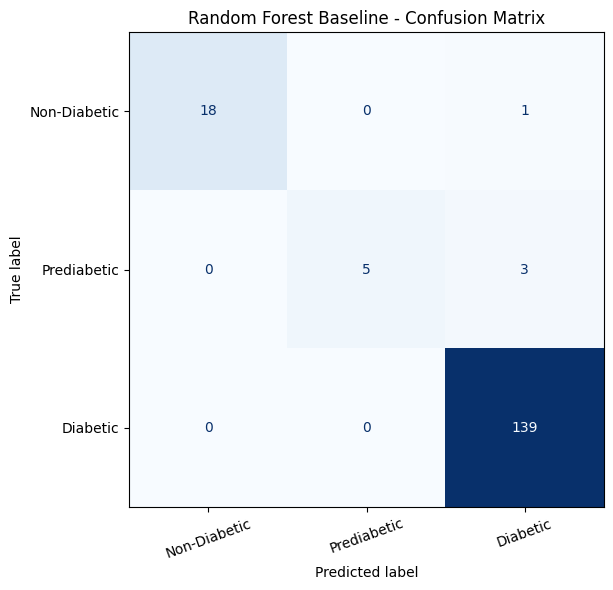

In [68]:
# Step 9 - Visualize confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

print("Confusion Matrix:")
print(cm)

# Create the visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Prediabetic", "Diabetic"]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Random Forest Baseline - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


The number of correctly classified records is 162 of 166 records correctly and 3 of 8 true prediabetic records are classified as diabetic.

The overall accuracy should always be used in conjunction with the per-class recall and the balanced accuracy.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
4,HbA1c,0.328023
10,BMI,0.257947
1,AGE,0.123895
5,Chol,0.081746
6,TG,0.050307
9,VLDL,0.038512
8,LDL,0.036262
3,Cr,0.025680
2,Urea,0.025318
7,HDL,0.023677


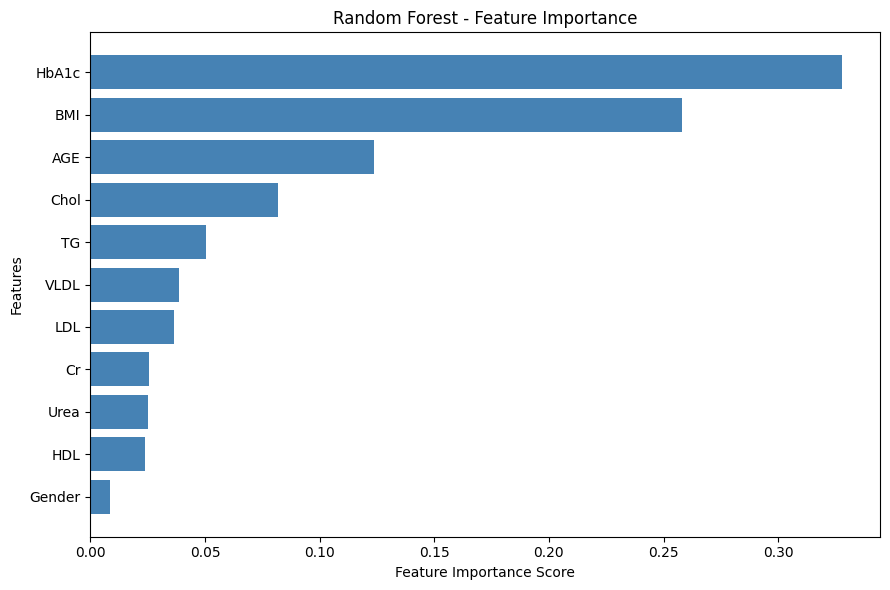

In [69]:
# Step 10 - Random Forest feature importance

import pandas as pd
import matplotlib.pyplot as plt

importance = rf_model.feature_importances_

# Create a table
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(feature_importance)

# Plot feature importance
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color="steelblue"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# 6. RF - Hyperparameter tuning

Train over 16 configurations * 5 stratified folds, select the best one based on training-CV macro-F1 (not test accuracy). The selected RF uses 100 trees, depth 8, leaf size 1 and no class weighting (CV macro-F1 **0.9270**). The predictions from tuned and untuned RF are equal on this held out split; tuning does not necessarily lead to better predictions in the test set

In [70]:
# Step 11 - Random Forest hyperparameter tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [None, 8],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("HYPERPARAMETER TUNING COMPLETED")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1-Score:")
print(round(grid_search.best_score_, 4))


HYPERPARAMETER TUNING COMPLETED

Best Parameters:
{'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 100}

Best Cross-Validation Macro F1-Score:
0.927


In [71]:
# Step 12 - Compare untuned and tuned Random Forest models

rf_tuned = grid_search.best_estimator_

y_pred_tuned = rf_tuned.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Untuned Random Forest", "Tuned Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tuned)
    ],

    "Macro Precision": [
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, y_pred_tuned, average="macro", zero_division=0)
    ],

    "Macro Recall": [
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred_tuned, average="macro", zero_division=0)
    ],

    "Macro F1": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred_tuned, average="macro", zero_division=0)
    ],

    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred_tuned)
    ]
})

print("UNTUNED VS TUNED RANDOM FOREST")
display(comparison.round(4))

print("\nTUNED MODEL CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=[0, 1, 2],
    target_names=["Non-Diabetic", "Prediabetic", "Diabetic"],
    zero_division=0
))


UNTUNED VS TUNED RANDOM FOREST


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Untuned Random Forest,0.9759,0.9907,0.8575,0.9093,0.8575
1,Tuned Random Forest,0.9759,0.9907,0.8575,0.9093,0.8575



TUNED MODEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

Non-Diabetic       1.00      0.95      0.97        19
 Prediabetic       1.00      0.62      0.77         8
    Diabetic       0.97      1.00      0.99       139

    accuracy                           0.98       166
   macro avg       0.99      0.86      0.91       166
weighted avg       0.98      0.98      0.97       166



**RF tuning outcome** - Training only five-fold GridSearchCV selects the specified configuration by macro-F1. Tuned and untuned RF give the same predictions on this held-out test set, no improvement is claimed from tuning here

# 7. Majority class control and comparison with the study

DummyClassifier compares if high accuracy is just because it is the majority class (Diabetic). The most well published ensemble by the authors is based on the combination of **k-NN, AdaBoost, DT and RF** (Table 9: **Accuracy 0.998, AUC 0.999**). The paper uses a slightly different data set and a different validation protocol so comparisons with our baseline are descriptive and not controlled head to head tests. The accuracy number in the above table is 0.998 which is not labeled AAC


In [72]:
# Step 13 - compare Random Forest with majority class baseline

from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)

# Calculate performance
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

dummy_f1 = f1_score(
    y_test, y_pred_dummy,
    average="macro",
    zero_division=0
)

dummy_balanced_acc = balanced_accuracy_score(
    y_test, y_pred_dummy
)

print("MAJORITY-CLASS BASELINE RESULTS")
print("--------------------------------")
print(f"Accuracy          : {dummy_accuracy:.4f}")
print(f"Macro F1-Score    : {dummy_f1:.4f}")
print(f"Balanced Accuracy : {dummy_balanced_acc:.4f}")

print("\nRANDOM FOREST VS MAJORITY BASELINE")

baseline_comparison = pd.DataFrame({
    "Model": ["Majority-Class Baseline", "Random Forest"],
    "Accuracy": [dummy_accuracy, accuracy],
    "Macro F1": [dummy_f1, f1],
    "Balanced Accuracy": [dummy_balanced_acc, balanced_acc]
})

display(baseline_comparison.round(4))


MAJORITY-CLASS BASELINE RESULTS
--------------------------------
Accuracy          : 0.8373
Macro F1-Score    : 0.3038
Balanced Accuracy : 0.3333

RANDOM FOREST VS MAJORITY BASELINE


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Majority-Class Baseline,0.8373,0.3038,0.3333
1,Random Forest,0.9759,0.9093,0.8575


In [73]:
# Step 14 - Compare baseline results with research paper

import pandas as pd
from sklearn.metrics import accuracy_score

# Results from my implementation
our_rf_accuracy = accuracy_score(y_test, y_pred)

# Source: table 9, best four-model ensemble
paper_ensemble_accuracy = 0.998

paper_comparison = pd.DataFrame({
    "Approach": [
        "Our Random Forest Baseline",
        "Authors' AUC-Weighted Ensemble"
    ],
    "Accuracy": [
        our_rf_accuracy,
        paper_ensemble_accuracy
    ],
    "Dataset": [
        "Public IPDD (826 profiles, no FBS)",
        "Authors' modified IPDD (993 records, with FBS)"
    ],
    "Evaluation": [
        "80/20 stratified train-test split",
        "Authors' cross-validation protocol"
    ]
})

print("BASELINE VS ORIGINAL RESEARCH PAPER")
print("-----------------------------------")

display(paper_comparison.round(4))

print("\nImportant:")
print("These results are NOT directly comparable.")
print("The datasets, features and evaluation methods differ.")

print("\nAdditional published result:")
print("Authors' Random Forest AAC: 0.988")
print("AAC is not identical to ordinary accuracy.")


BASELINE VS ORIGINAL RESEARCH PAPER
-----------------------------------


,Approach,Accuracy,Dataset,Evaluation
0,Our Random Forest Baseline,0.9759,"Public IPDD (826 profiles, no FBS)",80/20 stratified train-test split
1,Authors' AUC-Weighted Ensemble,0.9980,"Authors' modified IPDD (993 records, with FBS)",Authors' cross-validation protocol



Important:
These results are NOT directly comparable.
The datasets, features and evaluation methods differ.

Additional published result:
Authors' Random Forest AAC: 0.988
AAC is not identical to ordinary accuracy.


# 8. ROC-AUC and Prediabetic precision-recall

Compute macro One-vs-One ROC-AUC and class-1 (Prediabetic vs rest) precision-recall/average precision.

An average precision of 1.0 indicates perfect ranking for the Prediabetic class in the one-vs-rest evaluation. However multiclass predictions use the highest probability across all three classes. So the model can still misclassify Prediabetic patients

In [74]:
# Step 15 - Calculate multiclass ROC-AUC Scores

from sklearn.metrics import roc_auc_score

y_proba = rf_model.predict_proba(X_test)

y_proba_tuned = rf_tuned.predict_proba(X_test)

# calculate One-vs-One Macro ROC-AUC
auc_untuned = roc_auc_score(
    y_test,
    y_proba,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

auc_tuned = roc_auc_score(
    y_test,
    y_proba_tuned,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

print("RANDOM FOREST ROC-AUC RESULTS")
print("--------------------------------")

print(f"Untuned Random Forest AUC: {auc_untuned:.4f}")
print(f"Tuned Random Forest AUC  : {auc_tuned:.4f}")

print("\nPublished Ensemble AUC: 0.999")
print("Note: Different datasets and evaluation methods.")


RANDOM FOREST ROC-AUC RESULTS
--------------------------------
Untuned Random Forest AUC: 0.9997
Tuned Random Forest AUC  : 0.9997

Published Ensemble AUC: 0.999
Note: Different datasets and evaluation methods.


PREDIABETIC CLASS EVALUATION
--------------------------------
Average Precision: 1.0000
Actual Prediabetic cases: 8


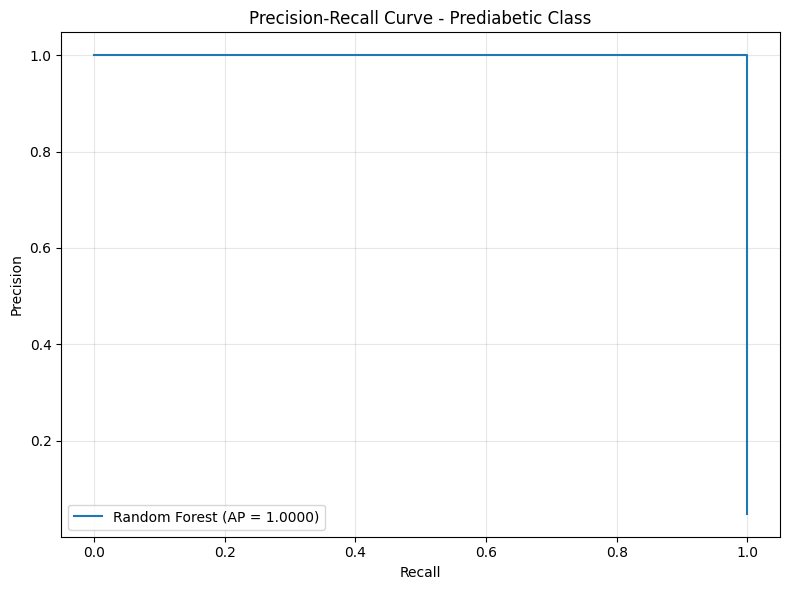

In [75]:
# Step 16 - Precision-recall analysis for prediabetic class

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

import matplotlib.pyplot as plt

# Prediabetic class = 1
y_test_prediabetic = (y_test == 1).astype(int)

prediabetic_index = list(rf_model.classes_).index(1)
prediabetic_prob = y_proba[:, prediabetic_index]

# Calculate Average Precision
ap_score = average_precision_score(
    y_test_prediabetic,
    prediabetic_prob
)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test_prediabetic,
    prediabetic_prob
)

print("PREDIABETIC CLASS EVALUATION")
print("--------------------------------")
print(f"Average Precision: {ap_score:.4f}")
print("Actual Prediabetic cases:",
      y_test_prediabetic.sum())

plt.figure(figsize=(8, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"Random Forest (AP = {ap_score:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Prediabetic Class")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [76]:
# Step 17 - Verify prediabetic Average Precision

check_ap = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred,
    "Prediabetic Probability": prediabetic_prob
})

prediabetic_cases = check_ap[
    check_ap["Actual Class"] == 1
]

print("ACTUAL PREDIABETIC PATIENTS")
display(prediabetic_cases)

# compare probability scores
min_positive = prediabetic_cases[
    "Prediabetic Probability"
].min()

max_negative = check_ap[
    check_ap["Actual Class"] != 1
]["Prediabetic Probability"].max()

print("\nLowest score among actual Prediabetic cases:",
      round(min_positive, 4))

print("Highest score among other classes:",
      round(max_negative, 4))

print("\nCorrectly classified Prediabetic cases:",
      (prediabetic_cases["Predicted Class"] == 1).sum(),
      "out of", len(prediabetic_cases))


ACTUAL PREDIABETIC PATIENTS


,Actual Class,Predicted Class,Prediabetic Probability
11,1,1,0.86
18,1,1,0.74
23,1,2,0.45
33,1,1,0.78
56,1,2,0.32
67,1,1,0.75
118,1,2,0.28
142,1,1,0.82



Lowest score among actual Prediabetic cases: 0.28
Highest score among other classes: 0.21

Correctly classified Prediabetic cases: 5 out of 8


An Average Precision of 1.0 means the Prediabetic probability scores perfectly rank the eight true Prediabetic cases above the others on this test set. Another class can have a higher probability for some of those records, producing a different multiclass argmax prediction.

In [77]:
# Step 18 - Analyse GridSearchCV hyperparameter results

import pandas as pd

# Convert GridSearchCV results into a DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

tuning_results = cv_results[[
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_leaf",
    "param_class_weight",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

tuning_results = tuning_results.sort_values(
    by=["rank_test_score", "mean_test_score"],
    ascending=[True, False]
)

print("GRIDSEARCHCV HYPERPARAMETER ANALYSIS")
print("------------------------------------")

print("Total configurations tested:", len(tuning_results))
print("Cross-validation folds:", grid_search.n_splits_)

print("\nTop 8 Hyperparameter Configurations:")
display(tuning_results.head(8).round(4))

print("\nBest Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Mean Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))


GRIDSEARCHCV HYPERPARAMETER ANALYSIS
------------------------------------
Total configurations tested: 16
Cross-validation folds: 5

Top 8 Hyperparameter Configurations:


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score,rank_test_score
4,100,8,1,None,0.9270,0.0294,1
1,150,None,1,None,0.9229,0.0266,2
8,100,None,1,balanced,0.9184,0.0470,3
9,150,None,1,balanced,0.9184,0.0470,3
0,100,None,1,None,0.9133,0.0318,5
11,150,None,2,balanced,0.9129,0.0245,6
15,150,8,2,balanced,0.9129,0.0245,6
6,100,8,2,None,0.9116,0.0419,8



Best Hyperparameters:
{'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 100}

Best Mean Cross-Validation Macro F1:
0.927


# 9. HbA1c ablation

Evaluate the same 11 predictors using a fixed parameter RF model as compared to a model of RF without HbA1c using the same training only five-fold CV.

 Macro-F1 changes from **0.9270 to 0.6464** even though there is no HbA1c information, suggesting a high degree of model dependence. It is not intended to confirm target leakage. The hyperparameters were selected beforehand with HbA1c present.This is an exploratory sensitivity analysis. It does not confirm leakage of the target


In [78]:
# Step 19 - HbA1c Feature Ablation experiment

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
import pandas as pd

X_with_hba1c = X_train.copy()

X_without_hba1c = X_train.drop(columns=["HbA1c"])

best_params = grid_search.best_params_.copy()

# Define 5-fold stratified cross validation
ablation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "prediabetic_recall": make_scorer(
        recall_score,
        labels=[1],
        average="macro",
        zero_division=0
    )
}

ablation_results = []

for name, features in [
    ("With HbA1c", X_with_hba1c),
    ("Without HbA1c", X_without_hba1c)
]:

    # Create a new RF
    model = RandomForestClassifier(
        **best_params,
        random_state=42,
        n_jobs=1
    )

    scores = cross_validate(
        model,
        features,
        y_train,
        cv=ablation_cv,
        scoring=scoring,
        n_jobs=-1
    )

    ablation_results.append({
        "Experiment": name,
        "Features": features.shape[1],
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Macro F1 Mean": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Prediabetic Recall": scores["test_prediabetic_recall"].mean()
    })

# Create comparison table
ablation_df = pd.DataFrame(ablation_results)

print("HbA1c FEATURE ABLATION EXPERIMENT")
print("---------------------------------")
print("Evaluation: 5-Fold CV on Training Data Only")

display(ablation_df.round(4))

print("\nMacro F1 Difference (With - Without HbA1c):")
difference = (
    ablation_df.loc[0, "Macro F1 Mean"]
    - ablation_df.loc[1, "Macro F1 Mean"]
)
print(round(difference, 4))


HbA1c FEATURE ABLATION EXPERIMENT
---------------------------------
Evaluation: 5-Fold CV on Training Data Only


,Experiment,Features,Accuracy Mean,Macro F1 Mean,Macro F1 SD,Balanced Accuracy,Prediabetic Recall
0,With HbA1c,11,0.9727,0.9270,0.0294,0.9142,0.8095
1,Without HbA1c,10,0.9258,0.6464,0.0344,0.6536,0.1238



Macro F1 Difference (With - Without HbA1c):
0.2806


**Ablation interpretation** - Same training only folds and preselected RF settings, the mean macro F1 decreases from 0.9270 to 0.6464 after removing HbA1c. This is a reflection of model dependence, not confirmed target leakage.

This is an exploratory ablation of the same data that was used for model tuning.

# 10. Data integrity and additional RF validation

Automated assertions validate labels, null/non-finite input, duplicate features on splits and conflicting target assignments. Nested CV outer = 5, inner = 3 is for the purposes of evaluating the hyperparameter values for RF, report the scores of each fold and mean ± SD. These checks cannot confirm patient identity, label construction or clinical generalizability

In [79]:
# Step 20 - Data integrity validation

import numpy as np

#check for identical feature profiles with conflicting labels
predictor_columns = X_train.columns.tolist()

conflicting_label_profiles = int((
    df_model.groupby(
        predictor_columns, dropna=False
    )[target_col].nunique() > 1
).sum())

train_test_overlap = len(
    X_train.merge(X_test, on=predictor_columns)
)

missing_cells = int(
    X_train.isna().sum().sum()
    + X_test.isna().sum().sum()
)

# check for NaN or infinite numeric values
non_finite_cells = int(
    (~np.isfinite(X_train.to_numpy(dtype=float))).sum()
    + (~np.isfinite(X_test.to_numpy(dtype=float))).sum()
)

print("DATA INTEGRITY VALIDATION")
print("-------------------------")

print("Cleaned dataset records:", len(df_model))

print("Conflicting label profiles:",
      conflicting_label_profiles)

print("Train/Test feature overlap:",
      train_test_overlap)

print("Missing feature values:", missing_cells)

print("Non-finite feature values:", non_finite_cells)

print("Available classes:",
      sorted(y.unique().tolist()))

assert set(y.unique()) == {0, 1, 2}, "Invalid class labels"

assert conflicting_label_profiles == 0, \
    "Conflicting labels detected"

assert train_test_overlap == 0, \
    "Train/Test feature overlap detected"

assert missing_cells == 0 and non_finite_cells == 0, \
    "Invalid feature values detected"

assert len(X_train) + len(X_test) == len(df_model), \
    "Train/Test sizes do not match"

print("\nAll data integrity checks passed!")


DATA INTEGRITY VALIDATION
-------------------------
Cleaned dataset records: 826
Conflicting label profiles: 0
Train/Test feature overlap: 0
Missing feature values: 0
Non-finite feature values: 0
Available classes: [0, 1, 2]

All data integrity checks passed!


In [80]:
# Step 21: Nested Cross-Validation for Random Forest

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate
)

# Define inner cross-validation for hyperparameter tuning
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# outer cross-validation for model evaluation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

nested_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

nested_grid = GridSearchCV(
    estimator=nested_rf,
    param_grid=grid_search.param_grid,
    scoring="f1_macro",
    cv=inner_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

nested_scores = cross_validate(
    estimator=nested_grid,
    X=X_train,
    y=y_train,
    cv=outer_cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "balanced_accuracy": "balanced_accuracy"
    },
    n_jobs=1,
    return_estimator=True,
    error_score="raise"
)

#  Display fold-wise results
nested_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": nested_scores["test_accuracy"],
    "Macro F1": nested_scores["test_macro_f1"],
    "Balanced Accuracy": nested_scores["test_balanced_accuracy"]
})

print("NESTED CROSS-VALIDATION RESULTS")
print("--------------------------------")
print("Outer folds: 5")
print("Inner folds: 3")
print("Hyperparameter configurations:",
      len(grid_search.cv_results_["params"]))

print("\nFold-wise Results:")
display(nested_results.round(4))

# Calculate mean and standard deviation
print("\nFINAL NESTED CV SUMMARY")

for metric in ["Accuracy", "Macro F1", "Balanced Accuracy"]:
    mean_score = nested_results[metric].mean()
    std_score = nested_results[metric].std(ddof=1)

    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")

print("\nBest Parameters Selected in Each Outer Fold:")

for fold, estimator in enumerate(
    nested_scores["estimator"], start=1
):
    print(f"Fold {fold}: {estimator.best_params_}")


NESTED CROSS-VALIDATION RESULTS
--------------------------------
Outer folds: 5
Inner folds: 3
Hyperparameter configurations: 16

Fold-wise Results:


,Fold,Accuracy,Macro F1,Balanced Accuracy
0,1,0.9621,0.8798,0.8222
1,2,0.9697,0.9077,0.8828
2,3,0.9621,0.9275,0.9670
3,4,0.9848,0.9606,0.9494
4,5,0.9697,0.9176,0.8987



FINAL NESTED CV SUMMARY
Accuracy: 0.9697 ± 0.0093
Macro F1: 0.9186 ± 0.0294
Balanced Accuracy: 0.9040 ± 0.0574

Best Parameters Selected in Each Outer Fold:
Fold 1: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}
Fold 2: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Fold 3: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Fold 4: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 150}
Fold 5: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}


# 11. Save models and verify the reusable RF pipeline

Save metrics, tuning/ablation tables, predictions and trained estimators. The full RF pipeline is implemented that is automatically encode the forest and compare the predictions to the manually encoded predictions and then compare the predictions generated after saving/reloading the forest with the automatically encoded predictions to see if they match. The figures are also exported for the report. There is no packaging at intermediate level. It is done at the end of the export

In [81]:
# Step 22: Save Trained Models and Experimental Results

from pathlib import Path
import joblib
import json
import shutil
import numpy as np
import pandas as pd
import sklearn
import matplotlib

# Create output folder
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    rf_model,
    output_dir / "random_forest_baseline.joblib"
)

joblib.dump(
    rf_tuned,
    output_dir / "random_forest_tuned.joblib"
)

comparison.to_csv(
    output_dir / "rf_model_comparison.csv",
    index=False
)

baseline_comparison.to_csv(
    output_dir / "majority_baseline_comparison.csv",
    index=False
)

paper_comparison.to_csv(
    output_dir / "research_paper_comparison.csv",
    index=False
)

# Save hyperparameter tuning results
tuning_results.to_csv(
    output_dir / "hyperparameter_tuning.csv",
    index=False
)

#  Save nested CV results
nested_results.to_csv(
    output_dir / "nested_cv_results.csv",
    index=False
)

# Save HbA1c ablation results
ablation_df.to_csv(
    output_dir / "hba1c_ablation.csv",
    index=False
)

feature_importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

# Save test predictions
test_predictions = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Untuned_RF": np.asarray(y_pred),
    "Tuned_RF": np.asarray(y_pred_tuned)
})

test_predictions.to_csv(
    output_dir / "test_predictions.csv",
    index=False
)

# save experiment configuration
experiment_info = {
    "dataset": "Public Iraqi Patient Dataset for Diabetes",
    "cleaned_records": int(len(df_model)),
    "train_records": int(len(X_train)),
    "test_records": int(len(X_test)),
    "feature_columns": X_train.columns.tolist(),
    "gender_mapping": {"F": 0, "M": 1},
    "class_mapping": {
        "N": 0,
        "P": 1,
        "Y": 2
    },
    "random_state": 42,
    "best_parameters": grid_search.best_params_,
    "best_cv_macro_f1": float(grid_search.best_score_),
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "matplotlib_version": matplotlib.__version__
}

with open(
    output_dir / "experiment_info.json", "w"
) as file:
    json.dump(experiment_info, file, indent=4)

loaded_model = joblib.load(
    output_dir / "random_forest_tuned.joblib"
)

assert np.array_equal(
    loaded_model.predict(X_test),
    y_pred_tuned
), "Saved model verification failed"

# All models/results are saved incrementally. The complete archive is
# created only once, after the Logistic Regression and ensemble steps.
print("PHASE 2 INTERMEDIATE RF OUTPUTS SAVED")
print("Reloaded tuned RF predictions: VERIFIED")
print("Files currently in result folder:")
for file in sorted(output_dir.iterdir()):
    print("-", file.name)


PHASE 2 INTERMEDIATE RF OUTPUTS SAVED
Reloaded tuned RF predictions: VERIFIED
Files currently in result folder:
- accuracy_auc_paper_comparison.png
- complete_rf_pipeline.joblib
- ensemble_auc_weights.json
- ensemble_model_results.csv
- ensemble_reproducibility_check.json
- ensemble_test_predictions.csv
- experiment_info.json
- feature_importance.csv
- final_model_accuracy_comparison.png
- final_models_vs_paper.csv
- hba1c_ablation.csv
- hyperparameter_tuning.csv
- logistic_regression_baseline.joblib
- logistic_regression_tuned.joblib
- lr_hyperparameter_tuning.csv
- lr_test_predictions.csv
- majority_baseline_comparison.csv
- nested_cv_results.csv
- prediabetic_pr_curve.png
- random_forest_baseline.joblib
- random_forest_tuned.joblib
- research_paper_comparison.csv
- rf_feature_importance.png
- rf_lr_model_comparison.csv
- rf_model_comparison.csv
- rf_vs_lr_confusion_matrices.png
- rf_vs_tuned_lr_confusion_matrices.png
- test_predictions.csv
- tuned_rf_confusion_matrix.png


In [82]:
# Step 23: Build and Test an End-to-End Random Forest Pipeline

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_train_raw = X.loc[X_train.index].copy()
X_test_raw = X.loc[X_test.index].copy()

numeric_columns = [
    col for col in X.columns if col != "Gender"
]

# Define preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "gender",
            OrdinalEncoder(categories=[["F", "M"]]),
            ["Gender"]
        ),
        (
            "numeric",
            "passthrough",
            numeric_columns
        )
    ]
)

# Combine preprocessing and Random Forest
rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    (
        "random_forest",
        RandomForestClassifier(
            **grid_search.best_params_,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_pipeline.fit(X_train_raw, y_train)

pipeline_predictions = rf_pipeline.predict(X_test_raw)

# Compare with the earlier tuned Random Forest
same_predictions = np.array_equal(
    pipeline_predictions,
    y_pred_tuned
)

print("END-TO-END PIPELINE VALIDATION")
print("--------------------------------")
print("Pipeline trained successfully!")
print("Pipeline test accuracy:",
      round(accuracy_score(y_test, pipeline_predictions), 4))

print("Predictions match previous tuned RF:",
      same_predictions)

sample = X_test_raw.iloc[[0]]

print("\nSample raw input:")
display(sample)

sample_prediction = rf_pipeline.predict(sample)[0]

print("Predicted class:", class_names[sample_prediction])

# Automated verification
assert same_predictions, "Pipeline predictions do not match"

print("\nAll pipeline verification checks passed!")


END-TO-END PIPELINE VALIDATION
--------------------------------
Pipeline trained successfully!
Pipeline test accuracy: 0.9759
Predictions match previous tuned RF: True

Sample raw input:


,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
306,F,52,7.6,84,8.1,4.2,2.0,0.7,2.6,0.9,36.0


Predicted class: Diabetic

All pipeline verification checks passed!


In [83]:
# Step 24: Save and Verify the Complete Prediction Pipeline

from pathlib import Path
import joblib
import numpy as np

output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

# Save the complete pipeline
pipeline_path = output_dir / "complete_rf_pipeline.joblib"

joblib.dump(rf_pipeline, pipeline_path)

print("Complete pipeline saved successfully!")

# Load the saved pipeline
loaded_pipeline = joblib.load(pipeline_path)

loaded_predictions = loaded_pipeline.predict(X_test_raw)

same_predictions = np.array_equal(
    loaded_predictions,
    pipeline_predictions
)

print("\nSAVED PIPELINE VERIFICATION")
print("---------------------------")

print("Saved file:", pipeline_path)
print("Predictions match:", same_predictions)

sample_raw = X_test_raw.iloc[[0]]

predicted_class = loaded_pipeline.predict(sample_raw)[0]

print("\nSample prediction:",
      class_names[predicted_class])

# Automated test
assert same_predictions, "Saved pipeline verification failed"

print("\nAll saved pipeline checks passed!")


Complete pipeline saved successfully!

SAVED PIPELINE VERIFICATION
---------------------------
Saved file: phase2_results/complete_rf_pipeline.joblib
Predictions match: True

Sample prediction: Diabetic

All saved pipeline checks passed!


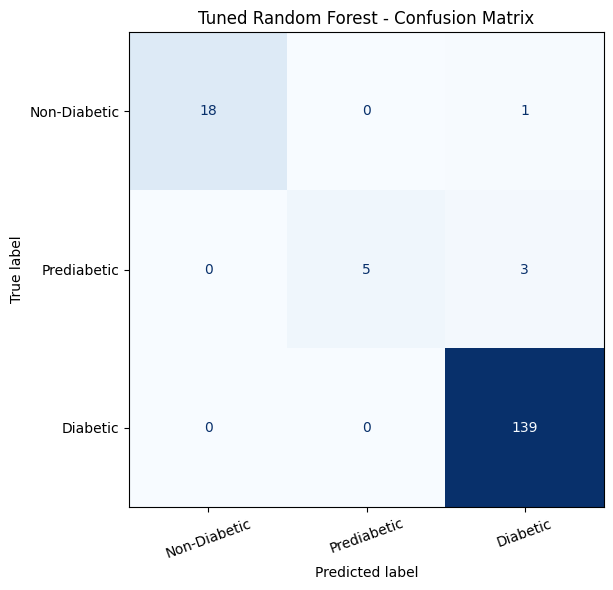

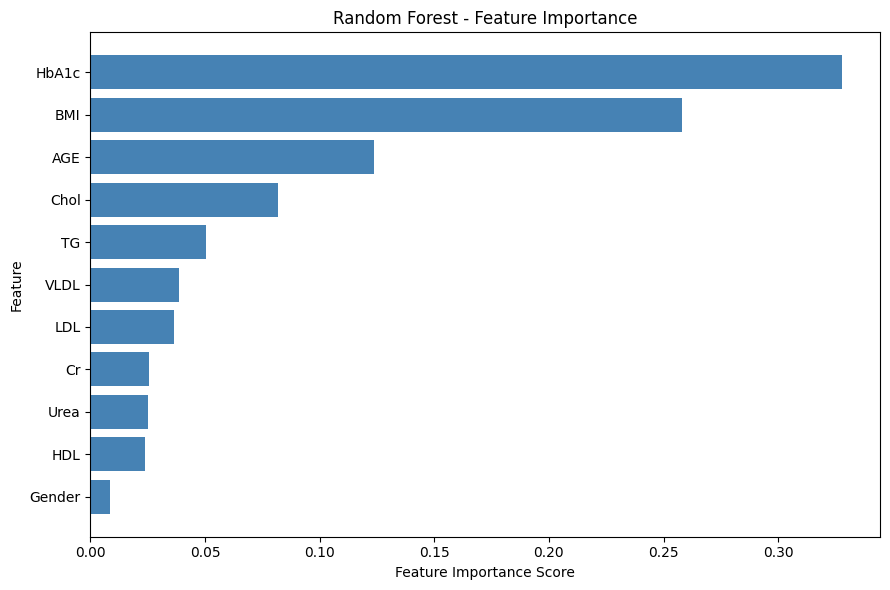

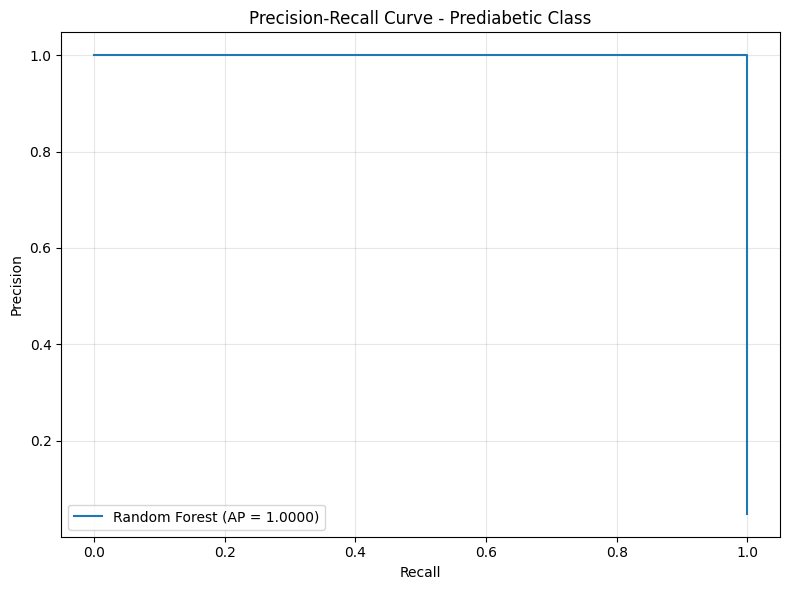


FIGURE SAVING VERIFICATION
--------------------------
Saved: tuned_rf_confusion_matrix.png
Saved: rf_feature_importance.png
Saved: prediabetic_pr_curve.png

All three figures saved successfully!


In [84]:
# Step 25: Save Evaluation Figures as PNG Files

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use the existing output folder
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

class_labels = ["Non-Diabetic", "Prediabetic", "Diabetic"]

# Save tuned Random Forest confusion matrix
cm_tuned = confusion_matrix(
    y_test, y_pred_tuned, labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=class_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Tuned Random Forest - Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=20)
fig.tight_layout()

fig.savefig(
    output_dir / "tuned_rf_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save feature importance graph
fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color="steelblue"
)

ax.invert_yaxis()
ax.set_xlabel("Feature Importance Score")
ax.set_ylabel("Feature")
ax.set_title("Random Forest - Feature Importance")
fig.tight_layout()

fig.savefig(
    output_dir / "rf_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save Prediabetic precision-recall curve
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    pr_recall,
    pr_precision,
    label=f"Random Forest (AP = {ap_score:.4f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve - Prediabetic Class")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    output_dir / "prediabetic_pr_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# verify all files exist
figure_names = [
    "tuned_rf_confusion_matrix.png",
    "rf_feature_importance.png",
    "prediabetic_pr_curve.png"
]

print("\nFIGURE SAVING VERIFICATION")
print("--------------------------")

for name in figure_names:
    file_path = output_dir / name

    assert file_path.exists()
    assert file_path.stat().st_size > 0

    print("Saved:", name)

print("\nAll three figures saved successfully!")


In [85]:
# Step 26: Compare Random Forest with the authors' ensemble

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Our Random Forest results
rf_untuned_acc = accuracy_score(y_test, y_pred)
rf_tuned_acc = accuracy_score(y_test, y_pred_tuned)

rf_untuned_f1 = f1_score(
    y_test, y_pred, average="macro"
)

rf_tuned_f1 = f1_score(
    y_test, y_pred_tuned, average="macro"
)

# Published results from Abnoosian et al. (2023)
# Table 9: Best AUC-weighted ensemble
paper_accuracy = 0.998
paper_auc = 0.999

#create comparison table
final_paper_comparison = pd.DataFrame({
    "Model": [
        "Our Untuned RF",
        "Our Tuned RF",
        "Authors' AUC-Weighted Ensemble"
    ],

    "Accuracy": [
        rf_untuned_acc,
        rf_tuned_acc,
        paper_accuracy
    ],

    "Macro F1": [
        rf_untuned_f1,
        rf_tuned_f1,
        None
    ],

    "ROC-AUC": [
        auc_untuned,
        auc_tuned,
        paper_auc
    ]
})

print("RF BASELINE VS AUTHORS' ADVANCED ENSEMBLE")
print("-----------------------------------------")

display(final_paper_comparison.round(4))

print("\nEXPERIMENTAL DIFFERENCES")
print("-----------------------------------------")

print("Our dataset: Public IPDD, 826 cleaned profiles")
print("Paper dataset: Modified IPDD, 993 records with FBS")

print("\nOur evaluation: Stratified 80/20 train-test split")
print("Paper evaluation: Authors' cross-validation")

print("\nOur AUC: Macro One-vs-One ROC-AUC")
print("Paper AUC: As reported in Table 9")

print("\nIMPORTANT:")
print("These results are descriptive, not a controlled comparison.")
print("Different datasets and protocols prevent direct superiority claims.")
print("Paper F1 is omitted because its averaging differs from Macro F1.")


RF BASELINE VS AUTHORS' ADVANCED ENSEMBLE
-----------------------------------------


,Model,Accuracy,Macro F1,ROC-AUC
0,Our Untuned RF,0.9759,0.9093,0.9997
1,Our Tuned RF,0.9759,0.9093,0.9997
2,Authors' AUC-Weighted Ensemble,0.9980,NaN,0.9990



EXPERIMENTAL DIFFERENCES
-----------------------------------------
Our dataset: Public IPDD, 826 cleaned profiles
Paper dataset: Modified IPDD, 993 records with FBS

Our evaluation: Stratified 80/20 train-test split
Paper evaluation: Authors' cross-validation

Our AUC: Macro One-vs-One ROC-AUC
Paper AUC: As reported in Table 9

IMPORTANT:
These results are descriptive, not a controlled comparison.
Different datasets and protocols prevent direct superiority claims.
Paper F1 is omitted because its averaging differs from Macro F1.


# 12. Logistic Regression (secondary baseline)

The LR pipeline is implemented with standard scalar for continuous predictors, OrdinalEncoder for Gender and LogisticRegression for multiclass prediction. Preprocessing is fitted just on the training data and then reused for test rows. Under the same train/test split, LR is a simpler linear decision boundary comparison, while RF is a nonlinear split

In [86]:
# Step 27: Create and train Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numeric columns
lr_numeric_columns = [
    col for col in X_train_raw.columns
    if col != "Gender"
]

lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "gender",
            OrdinalEncoder(categories=[["F", "M"]]),
            ["Gender"]
        ),
        (
            "numeric",
            StandardScaler(),
            lr_numeric_columns
        )
    ]
)

#  Create Logistic Regression pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessing", lr_preprocessor),
    ("logistic_regression", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train_raw, y_train)

print("LOGISTIC REGRESSION BASELINE")
print("----------------------------")
print("Model trained successfully!")

print("Training samples:", len(X_train_raw))
print("Input features:", X_train_raw.shape[1])
print("Classes learned:", lr_pipeline.classes_)

print("\nPipeline:")
print(lr_pipeline)


LOGISTIC REGRESSION BASELINE
----------------------------
Model trained successfully!
Training samples: 660
Input features: 11
Classes learned: [0 1 2]

Pipeline:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('gender',
                                                  OrdinalEncoder(categories=[['F',
                                                                              'M']]),
                                                  ['Gender']),
                                                 ('numeric', StandardScaler(),
                                                  ['AGE', 'Urea', 'Cr', 'HbA1c',
                                                   'Chol', 'TG', 'HDL', 'LDL',
                                                   'VLDL', 'BMI'])])),
                ('logistic_regression',
                 LogisticRegression(max_iter=3000, random_state=42))])


In [87]:
# Step 28: Evaluate Logistic Regression and compare with RF

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report
)

y_pred_lr = lr_pipeline.predict(X_test_raw)

y_proba_lr = lr_pipeline.predict_proba(X_test_raw)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test, y_pred_lr, average="macro", zero_division=0
)

lr_recall = recall_score(
    y_test, y_pred_lr, average="macro", zero_division=0
)

lr_f1 = f1_score(
    y_test, y_pred_lr, average="macro", zero_division=0
)

lr_balanced_acc = balanced_accuracy_score(
    y_test, y_pred_lr
)

lr_auc = roc_auc_score(
    y_test,
    y_proba_lr,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

#  Display LR performance
print("LOGISTIC REGRESSION TEST RESULTS")
print("--------------------------------")
print(f"Accuracy          : {lr_accuracy:.4f}")
print(f"Macro Precision   : {lr_precision:.4f}")
print(f"Macro Recall      : {lr_recall:.4f}")
print(f"Macro F1-Score    : {lr_f1:.4f}")
print(f"Balanced Accuracy : {lr_balanced_acc:.4f}")
print(f"Macro OVO ROC-AUC : {lr_auc:.4f}")

print("\nDETAILED LOGISTIC REGRESSION REPORT")
print("-----------------------------------")

print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1, 2],
    target_names=["Non-Diabetic", "Prediabetic", "Diabetic"],
    zero_division=0
))

rf_lr_comparison = pd.DataFrame({
    "Model": ["Tuned Random Forest", "Logistic Regression"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_tuned),
        lr_accuracy
    ],

    "Macro F1": [
        f1_score(y_test, y_pred_tuned, average="macro"),
        lr_f1
    ],

    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, y_pred_tuned),
        lr_balanced_acc
    ],

    "Macro OVO AUC": [
        auc_tuned,
        lr_auc
    ]
})

print("\nRANDOM FOREST VS LOGISTIC REGRESSION")
display(rf_lr_comparison.round(4))


LOGISTIC REGRESSION TEST RESULTS
--------------------------------
Accuracy          : 0.9337
Macro Precision   : 0.7799
Macro Recall      : 0.6684
Macro F1-Score    : 0.6865
Balanced Accuracy : 0.6684
Macro OVO ROC-AUC : 0.9324

DETAILED LOGISTIC REGRESSION REPORT
-----------------------------------
              precision    recall  f1-score   support

Non-Diabetic       0.89      0.89      0.89        19
 Prediabetic       0.50      0.12      0.20         8
    Diabetic       0.94      0.99      0.96       139

    accuracy                           0.93       166
   macro avg       0.78      0.67      0.69       166
weighted avg       0.92      0.93      0.92       166


RANDOM FOREST VS LOGISTIC REGRESSION


,Model,Accuracy,Macro F1,Balanced Accuracy,Macro OVO AUC
0,Tuned Random Forest,0.9759,0.9093,0.8575,0.9997
1,Logistic Regression,0.9337,0.6865,0.6684,0.9324


TUNED RANDOM FOREST CONFUSION MATRIX
[[ 18   0   1]
 [  0   5   3]
 [  0   0 139]]

LOGISTIC REGRESSION CONFUSION MATRIX
[[ 17   0   2]
 [  1   1   6]
 [  1   1 137]]


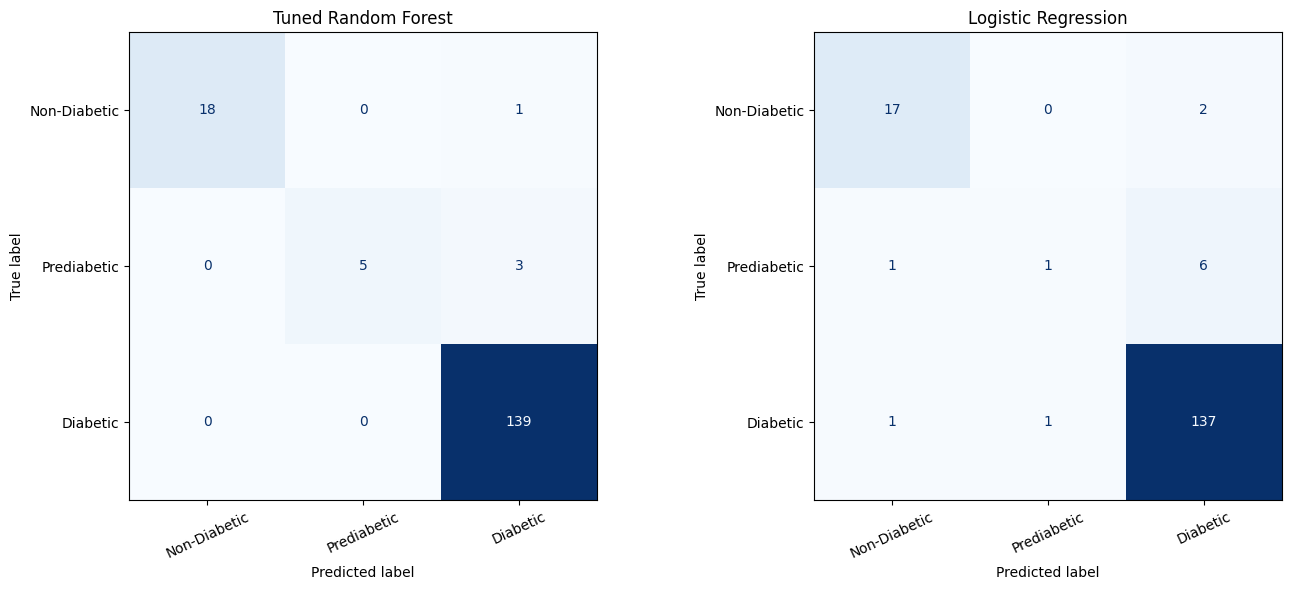


Comparison figure saved successfully!


In [88]:
# Step 29: Compare RF and LR confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

labels = ["Non-Diabetic", "Prediabetic", "Diabetic"]

cm_rf = confusion_matrix(
    y_test, y_pred_tuned, labels=[0, 1, 2]
)

cm_lr = confusion_matrix(
    y_test, y_pred_lr, labels=[0, 1, 2]
)

# Print both matrices
print("TUNED RANDOM FOREST CONFUSION MATRIX")
print(cm_rf)

print("\nLOGISTIC REGRESSION CONFUSION MATRIX")
print(cm_lr)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=labels
)

disp_rf.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Tuned Random Forest")
axes[0].tick_params(axis="x", rotation=25)

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=labels
)

disp_lr.plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[1].set_title("Logistic Regression")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()

# Save comparison figure
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "rf_vs_lr_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nComparison figure saved successfully!")


# 13. LR tuning and comparison with RF

Tune LR using **five-fold training CV**, macro-F1 selection, `C ∈ {0.01, 0.1, 1, 10}` and `class_weight ∈ {None, balanced}`.

The optimal training-CV settings are `C=10` and `balanced` (which is the reason why we don't claim any optimality as the search bound is limited). On this test split, RF accuracy/macro-F1 is higher while tuned LR's balanced accuracy and Prediabetic recall are higher with lower Prediabetic precision. Keep the test set for reporting, don't re-sample the settings in the test set.

In [89]:
# Step 30: Logistic Regression Hyperparameter Tuning

import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold

lr_param_grid = {
    "logistic_regression__C": [0.01, 0.1, 1.0, 10.0],
    "logistic_regression__class_weight": [None, "balanced"]
}

lr_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create GridSearchCV for the entire LR pipeline
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=lr_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

lr_grid_search.fit(X_train_raw, y_train)

print("LOGISTIC REGRESSION HYPERPARAMETER TUNING")
print("----------------------------------------")

print("Configurations tested:",
      len(lr_grid_search.cv_results_["params"]))

print("Cross-validation folds:", lr_grid_search.n_splits_)

print("\nBest Parameters:")
print(lr_grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(lr_grid_search.best_score_, 4))

# Display all parameter configurations
lr_tuning_results = pd.DataFrame(
    lr_grid_search.cv_results_
)[[
    "param_logistic_regression__C",
    "param_logistic_regression__class_weight",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]]

lr_tuning_results = lr_tuning_results.sort_values(
    by="rank_test_score"
)

print("\nHyperparameter Comparison:")
display(lr_tuning_results.round(4))


LOGISTIC REGRESSION HYPERPARAMETER TUNING
----------------------------------------
Configurations tested: 8
Cross-validation folds: 5

Best Parameters:
{'logistic_regression__C': 10.0, 'logistic_regression__class_weight': 'balanced'}

Best Cross-Validation Macro F1:
0.7661

Hyperparameter Comparison:


,param_logistic_regression__C,param_logistic_regression__class_weight,mean_test_score,std_test_score,rank_test_score
7,10.00,balanced,0.7661,0.0495,1
5,1.00,balanced,0.7605,0.0335,2
3,0.10,balanced,0.7224,0.0588,3
4,1.00,None,0.6590,0.0334,4
1,0.01,balanced,0.6415,0.0312,5
6,10.00,None,0.6292,0.0273,6
2,0.10,None,0.5890,0.0111,7
0,0.01,None,0.5010,0.0346,8


In [90]:
# Step 31: Evaluate tuned Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report
)
import pandas as pd

lr_tuned = lr_grid_search.best_estimator_

y_pred_lr_tuned = lr_tuned.predict(X_test_raw)

y_proba_lr_tuned = lr_tuned.predict_proba(X_test_raw)

lr_tuned_accuracy = accuracy_score(
    y_test, y_pred_lr_tuned
)

lr_tuned_f1 = f1_score(
    y_test, y_pred_lr_tuned,
    average="macro", zero_division=0
)

lr_tuned_balanced_acc = balanced_accuracy_score(
    y_test, y_pred_lr_tuned
)

lr_tuned_auc = roc_auc_score(
    y_test,
    y_proba_lr_tuned,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

#Display tuned LR results
print("TUNED LOGISTIC REGRESSION RESULTS")
print("---------------------------------")

print(f"Accuracy          : {lr_tuned_accuracy:.4f}")
print(f"Macro F1          : {lr_tuned_f1:.4f}")
print(f"Balanced Accuracy : {lr_tuned_balanced_acc:.4f}")
print(f"Macro OVO ROC-AUC : {lr_tuned_auc:.4f}")

print("\nTUNED LR CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_lr_tuned,
    labels=[0, 1, 2],
    target_names=[
        "Non-Diabetic",
        "Prediabetic",
        "Diabetic"
    ],
    zero_division=0
))

# Compare all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Untuned Logistic Regression",
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        lr_tuned_accuracy,
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Macro F1": [
        lr_f1,
        lr_tuned_f1,
        f1_score(y_test, y_pred_tuned, average="macro")
    ],
    "Balanced Accuracy": [
        lr_balanced_acc,
        lr_tuned_balanced_acc,
        balanced_accuracy_score(y_test, y_pred_tuned)
    ],
    "Macro OVO AUC": [
        lr_auc,
        lr_tuned_auc,
        auc_tuned
    ],
    "Prediabetic Recall": [
        recall_score(
            y_test, y_pred_lr,
            labels=[1], average="macro"
        ),
        recall_score(
            y_test, y_pred_lr_tuned,
            labels=[1], average="macro"
        ),
        recall_score(
            y_test, y_pred_tuned,
            labels=[1], average="macro"
        )
    ]
})

print("\nFINAL BASELINE MODEL COMPARISON")
display(model_comparison.round(4))


TUNED LOGISTIC REGRESSION RESULTS
---------------------------------
Accuracy          : 0.9398
Macro F1          : 0.8340
Balanced Accuracy : 0.9216
Macro OVO ROC-AUC : 0.9836

TUNED LR CLASSIFICATION REPORT
              precision    recall  f1-score   support

Non-Diabetic       0.90      0.95      0.92        19
 Prediabetic       0.47      0.88      0.61         8
    Diabetic       1.00      0.94      0.97       139

    accuracy                           0.94       166
   macro avg       0.79      0.92      0.83       166
weighted avg       0.96      0.94      0.95       166


FINAL BASELINE MODEL COMPARISON


,Model,Accuracy,Macro F1,Balanced Accuracy,Macro OVO AUC,Prediabetic Recall
0,Untuned Logistic Regression,0.9337,0.6865,0.6684,0.9324,0.125
1,Tuned Logistic Regression,0.9398,0.8340,0.9216,0.9836,0.875
2,Tuned Random Forest,0.9759,0.9093,0.8575,0.9997,0.625


TUNED RANDOM FOREST CONFUSION MATRIX
[[ 18   0   1]
 [  0   5   3]
 [  0   0 139]]

TUNED LOGISTIC REGRESSION CONFUSION MATRIX
[[ 18   1   0]
 [  1   7   0]
 [  1   7 131]]


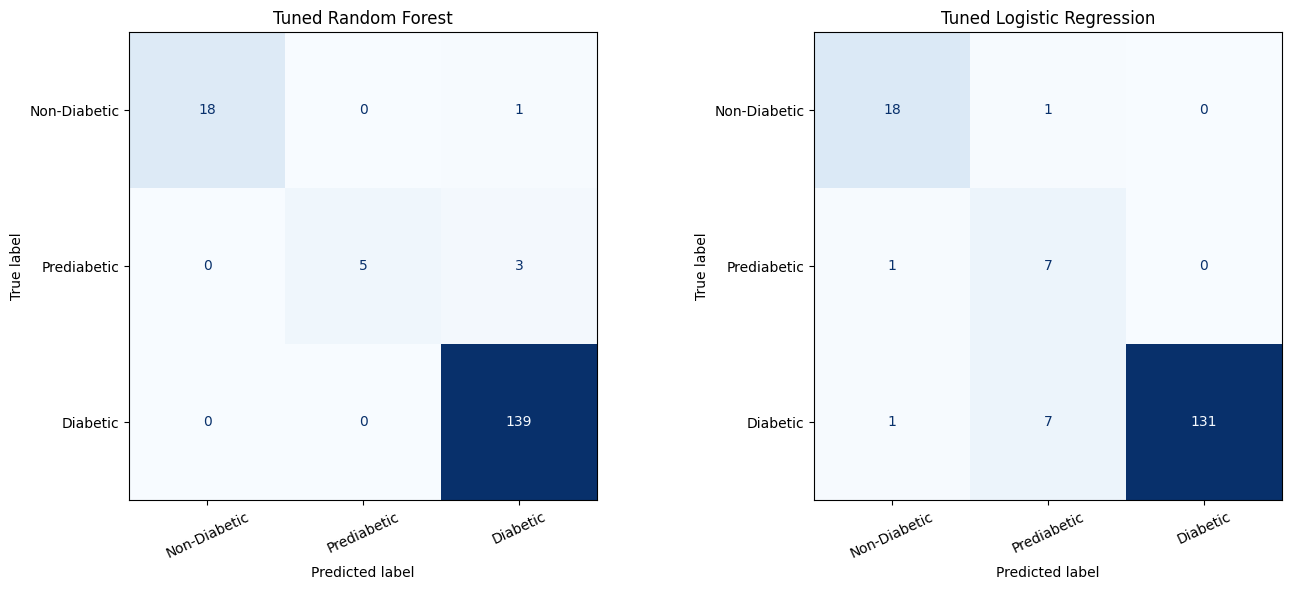


Final tuned-model comparison figure saved!


In [91]:
# Step 32: compare tuned RF and tuned LR confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

# Define class labels
class_labels = ["Non-Diabetic", "Prediabetic", "Diabetic"]

cm_rf_tuned = confusion_matrix(
    y_test, y_pred_tuned, labels=[0, 1, 2]
)

cm_lr_tuned = confusion_matrix(
    y_test, y_pred_lr_tuned, labels=[0, 1, 2]
)

print("TUNED RANDOM FOREST CONFUSION MATRIX")
print(cm_rf_tuned)

print("\nTUNED LOGISTIC REGRESSION CONFUSION MATRIX")
print(cm_lr_tuned)

# Create side-by-side graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_tuned,
    display_labels=class_labels
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Tuned Random Forest")
axes[0].tick_params(axis="x", rotation=25)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_tuned,
    display_labels=class_labels
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[1].set_title("Tuned Logistic Regression")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()

# Save figure
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "rf_vs_tuned_lr_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFinal tuned-model comparison figure saved!")


In [92]:
# Step 33: Save and verify Logistic Regression models

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# Use the existing results folder
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    lr_pipeline,
    output_dir / "logistic_regression_baseline.joblib"
)

joblib.dump(
    lr_tuned,
    output_dir / "logistic_regression_tuned.joblib"
)

# Save LR tuning results
lr_tuning_results.to_csv(
    output_dir / "lr_hyperparameter_tuning.csv",
    index=False
)

model_comparison.to_csv(
    output_dir / "rf_lr_model_comparison.csv",
    index=False
)

lr_predictions = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Untuned_LR": np.asarray(y_pred_lr),
    "Tuned_LR": np.asarray(y_pred_lr_tuned)
})

lr_predictions.to_csv(
    output_dir / "lr_test_predictions.csv",
    index=False
)

loaded_lr = joblib.load(
    output_dir / "logistic_regression_tuned.joblib"
)

loaded_lr_predictions = loaded_lr.predict(X_test_raw)

same_predictions = np.array_equal(
    loaded_lr_predictions,
    y_pred_lr_tuned
)

assert same_predictions, "Saved LR prediction mismatch"

print("LOGISTIC REGRESSION SAVING VERIFICATION")
print("---------------------------------------")

print("Untuned LR saved: YES")
print("Tuned LR saved: YES")
print("LR tuning results saved: YES")
print("RF vs LR comparison saved: YES")
print("LR test predictions saved: YES")

print("\nReloaded model predictions match:",
      same_predictions)

print("\nAll Logistic Regression saving checks passed!")


LOGISTIC REGRESSION SAVING VERIFICATION
---------------------------------------
Untuned LR saved: YES
Tuned LR saved: YES
LR tuning results saved: YES
RF vs LR comparison saved: YES
LR test predictions saved: YES

Reloaded model predictions match: True

All Logistic Regression saving checks passed!


# 14. Exploratory two model AUC-weighted ensemble

AUC weights are calculated using training-only out-of-fold predictions with nested cross-validation (5 outer folds and 3 inner folds). Macro One-vs-One ROC-AUC scores are normalized to obtain ensemble weights. The held-out test set is used only for final evaluation. This is an exploratory two-model ensemble, not an exact reproduction of the authors' four-model ensemble.

In [93]:
# Step 34: Calculate Training-Only AUC weights
# for RF + LR ensemble

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import roc_auc_score

#  Outer CV for out-of-fold predictions
ensemble_outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#  Inner CV for hyperparameter selection
ensemble_inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

#  RF tuning inside each outer training fold
rf_inner_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=grid_search.param_grid,
    scoring="f1_macro",
    cv=ensemble_inner_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

# LR tuning inside each outer training fold
lr_inner_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=ensemble_inner_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

#  Obtain RF out-of-fold probabilities
rf_oof_proba = cross_val_predict(
    rf_inner_search,
    X_train,
    y_train,
    cv=ensemble_outer_cv,
    method="predict_proba",
    n_jobs=1
)

#  Obtain LR out-of-fold probabilities
lr_oof_proba = cross_val_predict(
    lr_inner_search,
    X_train_raw,
    y_train,
    cv=ensemble_outer_cv,
    method="predict_proba",
    n_jobs=1
)

#  Calculate Macro One-vs-One ROC-AUC
rf_oof_auc = roc_auc_score(
    y_train,
    rf_oof_proba,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

lr_oof_auc = roc_auc_score(
    y_train,
    lr_oof_proba,
    multi_class="ovo",
    average="macro",
    labels=[0, 1, 2]
)

#  Normalize AUC values into weights
auc_weights = np.array([
    rf_oof_auc,
    lr_oof_auc
])

auc_weights = auc_weights / auc_weights.sum()

rf_weight, lr_weight = auc_weights

print("TRAINING-ONLY AUC WEIGHT ESTIMATION")
print("-----------------------------------")

print(f"RF Out-of-Fold AUC : {rf_oof_auc:.4f}")
print(f"LR Out-of-Fold AUC : {lr_oof_auc:.4f}")

print("\nNormalized Ensemble Weights:")
print(f"Random Forest       : {rf_weight:.4f}")
print(f"Logistic Regression : {lr_weight:.4f}")

print("\nTotal Weight:",
      round(auc_weights.sum(), 4))

assert np.isfinite(auc_weights).all()
assert np.isclose(auc_weights.sum(), 1.0)

print("\nAUC weights calculated successfully!")


TRAINING-ONLY AUC WEIGHT ESTIMATION
-----------------------------------
RF Out-of-Fold AUC : 0.9967
LR Out-of-Fold AUC : 0.9543

Normalized Ensemble Weights:
Random Forest       : 0.5109
Logistic Regression : 0.4891

Total Weight: 1.0

AUC weights calculated successfully!


# 15. Compare equal and AUC-weighted probability averaging

Combine class probabilities of RF and LR using 50-50 combination or using the AUC weights learned during training. Take the class with the greatest total probability for each patient. Compare both ensembles with the individual tuned ensembles on the same held out records and metrics. This is an exploratory (not the exact four-classifier pipeline) adaptation of predicted probabilities - not the actual pipeline found in the paper

In [94]:
# Step 35: Equal-Weight vs AUC-Weighted ensemble

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score
)

assert np.array_equal(
    rf_tuned.classes_,
    lr_tuned.classes_
), "Model class orders do not match"

class_order = rf_tuned.classes_

assert np.array_equal(
    class_order, [0, 1, 2]
), "Unexpected class order"

# Get probabilities from both tuned models
rf_proba = rf_tuned.predict_proba(X_test)

lr_proba = lr_tuned.predict_proba(X_test_raw)

assert rf_proba.shape == lr_proba.shape

assert np.allclose(rf_proba.sum(axis=1), 1.0)
assert np.allclose(lr_proba.sum(axis=1), 1.0)

# Equal-Weight ensemble (50% + 50%)
equal_proba = (
    0.5 * rf_proba +
    0.5 * lr_proba
)

# AUC-Weighted ensemble
auc_ensemble_proba = (
    rf_weight * rf_proba +
    lr_weight * lr_proba
)

# Convert combined probabilities into predictions
y_pred_equal = class_order[
    np.argmax(equal_proba, axis=1)
]

y_pred_auc_ensemble = class_order[
    np.argmax(auc_ensemble_proba, axis=1)
]

def evaluate_ensemble(name, predictions, probabilities):

    return {
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),

        "Prediabetic Recall": recall_score(
            y_test, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        ),

        "Macro OVO AUC": roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovo",
            average="macro",
            labels=[0, 1, 2]
        )
    }

# Compare all four models
ensemble_comparison = pd.DataFrame([
    evaluate_ensemble(
        "Tuned Random Forest",
        y_pred_tuned,
        rf_proba
    ),

    evaluate_ensemble(
        "Tuned Logistic Regression",
        y_pred_lr_tuned,
        lr_proba
    ),

    evaluate_ensemble(
        "Equal-Weight Ensemble",
        y_pred_equal,
        equal_proba
    ),

    evaluate_ensemble(
        "AUC-Weighted Ensemble",
        y_pred_auc_ensemble,
        auc_ensemble_proba
    )
])

print("ENSEMBLE PERFORMANCE COMPARISON")
print("--------------------------------")

display(ensemble_comparison.round(4))

# Compare ensemble predictions
different_predictions = np.sum(
    y_pred_equal != y_pred_auc_ensemble
)

print("\nDifferent predictions between ensembles:",
      different_predictions)

print("\nAUC Weights:")
print(f"Random Forest: {rf_weight:.4f}")
print(f"Logistic Regression: {lr_weight:.4f}")

assert np.allclose(equal_proba.sum(axis=1), 1.0)

assert np.allclose(
    auc_ensemble_proba.sum(axis=1), 1.0
)

print("\nBoth ensembles evaluated successfully!")


ENSEMBLE PERFORMANCE COMPARISON
--------------------------------


,Model,Accuracy,Macro F1,Balanced Accuracy,Prediabetic Recall,Macro OVO AUC
0,Tuned Random Forest,0.9759,0.9093,0.8575,0.625,0.9997
1,Tuned Logistic Regression,0.9398,0.8340,0.9216,0.875,0.9836
2,Equal-Weight Ensemble,0.9699,0.9176,0.9336,0.875,0.9970
3,AUC-Weighted Ensemble,0.9699,0.9176,0.9336,0.875,0.9971



Different predictions between ensembles: 0

AUC Weights:
Random Forest: 0.5109
Logistic Regression: 0.4891

Both ensembles evaluated successfully!


# 16. Final model and published paper comparison

Macro-F1 is 0.9176 and the accuracy is 0.9699 with equal weight and AUC weighted ensembles locally on 166 test records, which yields the same class labels. so these results are not based on an AUC weighted classification gain. Tables and plots separately identify the authors' published 0.998 Accuracy / 0.999 AUC. They use different averaging and datasets; macro-F1 is therefore not compared with a supposedly similar published macro-F1

In [95]:
# Step 36: Save final ensemble results and paper comparison

from pathlib import Path
import pandas as pd
import numpy as np
import json

output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

# Prepare results from our four implemented models
our_results = ensemble_comparison.copy()

our_results = our_results.rename(
    columns={"Macro OVO AUC": "AUC"}
)

our_results["Source"] = "Our Implementation"
our_results["Evaluation"] = "80/20 Stratified Hold-out Test"
our_results["AUC Method"] = "Macro OVO"

# Add the authors' published best ensemble results
# Abnoosian et al. (2023), Table 9

paper_results = pd.DataFrame([{
    "Model": "Authors' AUC-Weighted Ensemble",
    "Accuracy": 0.998,
    "Macro F1": np.nan,
    "Balanced Accuracy": np.nan,
    "Prediabetic Recall": np.nan,
    "AUC": 0.999,
    "Source": "Published Research Paper",
    "Evaluation": "Authors' Cross-Validation",
    "AUC Method": "Paper-reported AUC"
}])

final_comparison = pd.concat(
    [our_results, paper_results],
    ignore_index=True
)

print("FINAL MODEL COMPARISON")
print("----------------------")

display(final_comparison.round(4).fillna("N/A"))

#  Save final comparison
final_comparison.to_csv(
    output_dir / "final_models_vs_paper.csv",
    index=False
)

ensemble_comparison.to_csv(
    output_dir / "ensemble_model_results.csv",
    index=False
)

ensemble_predictions = pd.DataFrame({
    "Actual_Class": np.asarray(y_test),
    "Tuned_RF": np.asarray(y_pred_tuned),
    "Tuned_LR": np.asarray(y_pred_lr_tuned),
    "Equal_Weight_Ensemble": np.asarray(y_pred_equal),
    "AUC_Weighted_Ensemble": np.asarray(y_pred_auc_ensemble)
})

ensemble_predictions.to_csv(
    output_dir / "ensemble_test_predictions.csv",
    index=False
)

# Save training-only AUC weights and configuration
weight_information = {
    "RF_OOF_AUC": float(rf_oof_auc),
    "LR_OOF_AUC": float(lr_oof_auc),
    "RF_Weight": float(rf_weight),
    "LR_Weight": float(lr_weight),
    "Weight_Source": "Training-only nested CV predictions",
    "Outer_Folds": 5,
    "Inner_Folds": 3,
    "AUC_Method": "Macro One-vs-One",
    "Ensemble_Members": [
        "Tuned Random Forest",
        "Tuned Logistic Regression"
    ],
    "Paper_DOI": "10.1186/s12859-023-05465-z"
}

with open(
    output_dir / "ensemble_auc_weights.json", "w"
) as file:
    json.dump(weight_information, file, indent=4)

# Verify saved files and prediction counts
required_outputs = [
    "final_models_vs_paper.csv",
    "ensemble_model_results.csv",
    "ensemble_test_predictions.csv",
    "ensemble_auc_weights.json"
]

for filename in required_outputs:
    assert (output_dir / filename).is_file()

assert len(ensemble_predictions) == len(y_test)

assert np.isclose(rf_weight + lr_weight, 1.0)

print("\nFINAL ENSEMBLE SAVING VERIFICATION")
print("----------------------------------")

for filename in required_outputs:
    print("Saved:", filename)

print("\nTest records verified:", len(ensemble_predictions))
print("AUC weight sum:", round(rf_weight + lr_weight, 4))

print("\nAll final ensemble results saved successfully!")


FINAL MODEL COMPARISON
----------------------


,Model,Accuracy,Macro F1,Balanced Accuracy,Prediabetic Recall,AUC,Source,Evaluation,AUC Method
0,Tuned Random Forest,0.9759,0.9093,0.8575,0.625,0.9997,Our Implementation,80/20 Stratified Hold-out Test,Macro OVO
1,Tuned Logistic Regression,0.9398,0.834,0.9216,0.875,0.9836,Our Implementation,80/20 Stratified Hold-out Test,Macro OVO
2,Equal-Weight Ensemble,0.9699,0.9176,0.9336,0.875,0.9970,Our Implementation,80/20 Stratified Hold-out Test,Macro OVO
3,AUC-Weighted Ensemble,0.9699,0.9176,0.9336,0.875,0.9971,Our Implementation,80/20 Stratified Hold-out Test,Macro OVO
4,Authors' AUC-Weighted Ensemble,0.9980,N/A,N/A,N/A,0.9990,Published Research Paper,Authors' Cross-Validation,Paper-reported AUC



FINAL ENSEMBLE SAVING VERIFICATION
----------------------------------
Saved: final_models_vs_paper.csv
Saved: ensemble_model_results.csv
Saved: ensemble_test_predictions.csv
Saved: ensemble_auc_weights.json

Test records verified: 166
AUC weight sum: 1.0

All final ensemble results saved successfully!


# 17. Reproducibility checks and exported visualizations

Restore both preprocessing + model pipelines and JSON AUC weights. Test the equal-weight/AUC-weight predictions created from **raw test rows** with the results of the previous steps and check that the labels and probabilities are identical. Document evidence of reproducibility, comparisons and figures in exports. Only load trusted models from 'joblib' and on matching versions of library

In [96]:
# Step 37: Verify saved ensemble reproducibility

from pathlib import Path
import numpy as np
import joblib
import json

output_dir = Path("phase2_results")

rf_path = output_dir / "complete_rf_pipeline.joblib"
lr_path = output_dir / "logistic_regression_tuned.joblib"
weights_path = output_dir / "ensemble_auc_weights.json"

# Verify saved files exist
for path in [rf_path, lr_path, weights_path]:
    assert path.is_file(), f"Missing file: {path}"

saved_rf = joblib.load(rf_path)
saved_lr = joblib.load(lr_path)

# Reload training-derived AUC weights
with open(weights_path, "r") as file:
    saved_config = json.load(file)

saved_rf_weight = saved_config["RF_Weight"]
saved_lr_weight = saved_config["LR_Weight"]

# Verify model class orders and weights
assert np.array_equal(
    saved_rf.classes_,
    saved_lr.classes_
)

assert np.array_equal(
    saved_rf.classes_, [0, 1, 2]
)

assert np.isclose(
    saved_rf_weight + saved_lr_weight, 1.0
)

saved_rf_proba = saved_rf.predict_proba(X_test_raw)

saved_lr_proba = saved_lr.predict_proba(X_test_raw)

# Reconstruct equal-weight ensemble
saved_equal_proba = (
    0.5 * saved_rf_proba +
    0.5 * saved_lr_proba
)

# Reconstruct AUC-weighted ensemble
saved_auc_proba = (
    saved_rf_weight * saved_rf_proba +
    saved_lr_weight * saved_lr_proba
)

classes = saved_rf.classes_

saved_equal_predictions = classes[
    np.argmax(saved_equal_proba, axis=1)
]

saved_auc_predictions = classes[
    np.argmax(saved_auc_proba, axis=1)
]

# Compare with original ensemble results
equal_match = np.array_equal(
    saved_equal_predictions,
    y_pred_equal
)

auc_match = np.array_equal(
    saved_auc_predictions,
    y_pred_auc_ensemble
)

probability_match = np.allclose(
    saved_auc_proba,
    auc_ensemble_proba,
    rtol=1e-10,
    atol=1e-12
)

print("SAVED ENSEMBLE REPRODUCIBILITY TEST")
print("-----------------------------------")

print("RF pipeline loaded: YES")
print("LR pipeline loaded: YES")
print("AUC weights loaded: YES")

print("\nEqual-weight predictions match:", equal_match)
print("AUC-weighted predictions match:", auc_match)
print("AUC-weighted probabilities match:", probability_match)

print("\nTest records checked:", len(X_test_raw))

print("\nLoaded Ensemble Weights:")
print(f"RF: {saved_rf_weight:.4f}")
print(f"LR: {saved_lr_weight:.4f}")

assert equal_match, "Equal-weight ensemble mismatch"
assert auc_match, "AUC-weighted ensemble mismatch"
assert probability_match, "Ensemble probabilities mismatch"

verification = {
    "test_records": int(len(X_test_raw)),
    "equal_predictions_match": bool(equal_match),
    "auc_predictions_match": bool(auc_match),
    "auc_probabilities_match": bool(probability_match),
    "rf_weight": float(saved_rf_weight),
    "lr_weight": float(saved_lr_weight)
}

with open(
    output_dir / "ensemble_reproducibility_check.json",
    "w"
) as file:
    json.dump(verification, file, indent=4)

print("\nAll saved ensemble verification checks passed!")


SAVED ENSEMBLE REPRODUCIBILITY TEST
-----------------------------------
RF pipeline loaded: YES
LR pipeline loaded: YES
AUC weights loaded: YES

Equal-weight predictions match: True
AUC-weighted predictions match: True
AUC-weighted probabilities match: True

Test records checked: 166

Loaded Ensemble Weights:
RF: 0.5109
LR: 0.4891

All saved ensemble verification checks passed!


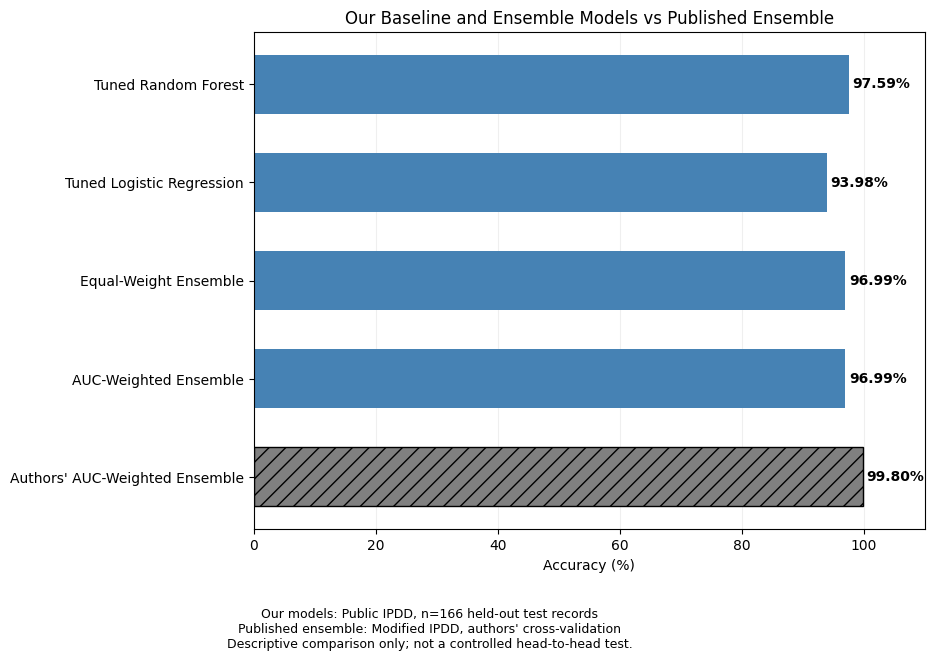

FINAL MODEL COMPARISON FIGURE
-----------------------------
Figure saved: phase2_results/final_model_accuracy_comparison.png
Models compared: 5

Visualization saved successfully!


In [97]:
# Step 38: Visualize final model accuracy comparison

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

plot_data = final_comparison.copy()

# Convert accuracy into percentages
plot_data["Accuracy (%)"] = (
    plot_data["Accuracy"].astype(float) * 100
)

is_published = (
    plot_data["Source"] == "Published Research Paper"
)

colors = [
    "gray" if published else "steelblue"
    for published in is_published
]

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data["Model"],
    plot_data["Accuracy (%)"],
    color=colors,
    height=0.6
)

for bar, published in zip(bars, is_published):
    if published:
        bar.set_hatch("//")
        bar.set_edgecolor("black")

# Add exact values to the bars
for bar, accuracy in zip(
    bars, plot_data["Accuracy (%)"]
):
    ax.text(
        accuracy + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{accuracy:.2f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Formatting
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("Accuracy (%)")
ax.set_title(
    "Our Baseline and Ensemble Models vs Published Ensemble"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5,
    0.02,
    "Our models: Public IPDD, n=166 held-out test records\n"
    "Published ensemble: Modified IPDD, authors' cross-validation\n"
    "Descriptive comparison only; not a controlled head-to-head test.",
    ha="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.34,
    right=0.95,
    top=0.90,
    bottom=0.19
)

# Save the figure
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

figure_path = (
    output_dir / "final_model_accuracy_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verify saved figure
assert figure_path.is_file()
assert figure_path.stat().st_size > 0

print("FINAL MODEL COMPARISON FIGURE")
print("-----------------------------")
print("Figure saved:", figure_path)
print("Models compared:", len(plot_data))
print("\nVisualization saved successfully!")


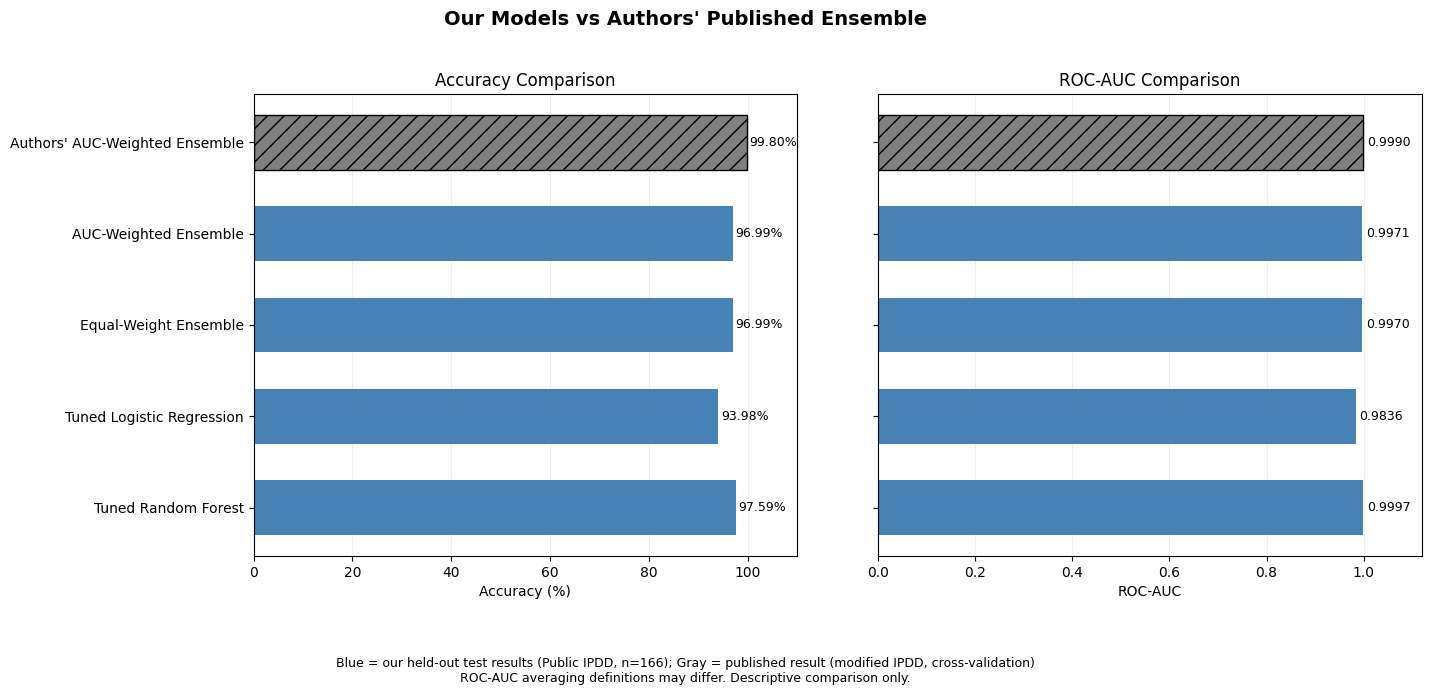

Accuracy and AUC comparison chart saved successfully!


In [98]:
# Step 39: Compare accuracy and ROC-AUC with original paper

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

chart_data = final_comparison.copy()

models = chart_data["Model"].tolist()
accuracy_values = chart_data["Accuracy"].astype(float) * 100
auc_values = chart_data["AUC"].astype(float)

# distinguish local models from the published model
colors = [
    "gray" if source == "Published Research Paper"
    else "steelblue"
    for source in chart_data["Source"]
]

# Create two comparison charts in one figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    sharey=True
)

metrics = [
    (accuracy_values, "Accuracy Comparison",
     "Accuracy (%)", 110, True),
    (auc_values, "ROC-AUC Comparison",
     "ROC-AUC", 1.12, False)
]

for ax, (values, title, xlabel, limit, is_percent) in zip(
    axes, metrics
):
    bars = ax.barh(
        models,
        values,
        color=colors,
        height=0.6
    )

    # Highlight published result
    bars[-1].set_hatch("//")
    bars[-1].set_edgecolor("black")

    # Add numeric values
    for bar, value in zip(bars, values):
        label = (
            f"{value:.2f}%"
            if is_percent else f"{value:.4f}"
        )

        offset = 0.6 if is_percent else 0.008

        ax.text(
            value + offset,
            bar.get_y() + bar.get_height() / 2,
            label,
            va="center",
            fontsize=9
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, limit)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Our Models vs Authors' Published Ensemble",
    fontsize=14,
    fontweight="bold"
)

fig.text(
    0.5, 0.02,
    "Blue = our held-out test results (Public IPDD, n=166); "
    "Gray = published result (modified IPDD, cross-validation)\n"
    "ROC-AUC averaging definitions may differ. "
    "Descriptive comparison only.",
    ha="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.23,
    right=0.96,
    wspace=0.15,
    bottom=0.20,
    top=0.86
)

# Save figure
output_dir = Path("phase2_results")
output_dir.mkdir(exist_ok=True)

chart_path = (
    output_dir / "accuracy_auc_paper_comparison.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("Accuracy and AUC comparison chart saved successfully!")


# 18. Final outputs and interpretation

Squeeze a package of trained pipelines, CSV data tables, configuration JSON and PNG figures into one verified Zipped file; store the source '.ipynb' on GitHub for later editing.

Limitations: public IPDD is different from the modified IPDD used in the paper, 174 removed profiles were not confirmed repeat patients, the Prediabetic test group consisted of only 8 cases, it is still not clear if the circularity of the two readings of HbA1c is a limitation, other ensembles were explored after seeing the held out results.  A detailed Phase 2 report will be available with the detailed architecture, library interactions, tuning analysis and screenshots

In [99]:
# Step 40: Create final complete phase 2 results ZIP

from pathlib import Path
import shutil
import zipfile

output_dir = Path("phase2_results")

assert output_dir.is_dir(), "Results folder not found"

required_files = [
    # Trained models
    "complete_rf_pipeline.joblib",
    "logistic_regression_tuned.joblib",

    # AUC-weighted ensemble configuration
    "ensemble_auc_weights.json",
    "ensemble_reproducibility_check.json",

    # Model evaluation and comparison
    "ensemble_model_results.csv",
    "final_models_vs_paper.csv",
    "ensemble_test_predictions.csv",
    "rf_lr_model_comparison.csv",

    # Hyperparameter tuning
    "hyperparameter_tuning.csv",
    "lr_hyperparameter_tuning.csv",

    # Additional experiments
    "nested_cv_results.csv",
    "hba1c_ablation.csv",

    # Visualizations
    "final_model_accuracy_comparison.png",
    "rf_vs_tuned_lr_confusion_matrices.png",
    "rf_feature_importance.png",
    "prediabetic_pr_curve.png",

    # Reproducibility information
    "experiment_info.json"
]

# Verify required files
missing_files = [
    name for name in required_files
    if not (output_dir / name).is_file()
]

assert not missing_files, (
    f"Missing required files: {missing_files}"
)

print("All essential output files verified!")

# Create final ZIP
zip_path = shutil.make_archive(
    "/content/phase2_complete_results_FINAL",
    "zip",
    root_dir=str(output_dir)
)

# Verify ZIP integrity and file contents
with zipfile.ZipFile(zip_path, "r") as archive:

    archived_files = archive.namelist()

    assert archive.testzip() is None, (
        "ZIP integrity verification failed"
    )

    missing_in_zip = [
        name for name in required_files
        if name not in archived_files
    ]

    assert not missing_in_zip, (
        f"Missing files in ZIP: {missing_in_zip}"
    )

print("\nFINAL PHASE 2 RESULTS PACKAGE")
print("--------------------------------")

print("Essential files verified:", len(required_files))
print("Total files in ZIP:", len(archived_files))
print("ZIP integrity: PASSED")
print("Final ZIP location:", zip_path)

print("\nSaved files:")
for filename in sorted(archived_files):
    print("-", filename)

print("\nFinal results package created successfully!")

# Download the final ZIP
from google.colab import files
files.download(zip_path)


All essential output files verified!

FINAL PHASE 2 RESULTS PACKAGE
--------------------------------
Essential files verified: 17
Total files in ZIP: 29
ZIP integrity: PASSED
Final ZIP location: /content/phase2_complete_results_FINAL.zip

Saved files:
- accuracy_auc_paper_comparison.png
- complete_rf_pipeline.joblib
- ensemble_auc_weights.json
- ensemble_model_results.csv
- ensemble_reproducibility_check.json
- ensemble_test_predictions.csv
- experiment_info.json
- feature_importance.csv
- final_model_accuracy_comparison.png
- final_models_vs_paper.csv
- hba1c_ablation.csv
- hyperparameter_tuning.csv
- logistic_regression_baseline.joblib
- logistic_regression_tuned.joblib
- lr_hyperparameter_tuning.csv
- lr_test_predictions.csv
- majority_baseline_comparison.csv
- nested_cv_results.csv
- prediabetic_pr_curve.png
- random_forest_baseline.joblib
- random_forest_tuned.joblib
- research_paper_comparison.csv
- rf_feature_importance.png
- rf_lr_model_comparison.csv
- rf_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>